# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [1]:
import numpy as np
from matplotlib import pyplot as plt
#Read in data set

In [2]:
#Read in data set
from scipy.io import readsav
filepath = '/home/vcvjet/Num_Met/NumAstro2026W_VeljkoCvjetkovic_12508316/galahamr.sav'  #change this to the path on your computer where the file is stored
try:
    stars = readsav(filepath) 
    print("Keys in the .sav file:")
    print(stars.keys())
    print(stars)
except FileNotFoundError as e:
    print("Error:", e)

Keys in the .sav file:
dict_keys(['f'])
{'f': rec.array([(52096, b'00000818-7717538',  583516992, 1.58, -0.118,  1.62 , 6011.5874, 3.98712, -0.070341, 1.255847,  6.66011,  31.895739,  0.002338, 1.654531,  0.      , -0.219701,  0.      , -0.000374, -0.056   , -0.012,  0.236313, 0.051118, -0.023216,  0.005074, 0.05919 , -0.108461,  0.      , 0., 0.,  0.      , 0.      ,  0.025611,  0.      , 0.,  0.      , 0., 0., 0.,  0.      , 0.      ,  0.      , 0., 0., 0., 5.50895, 1.141413, -0.362933,  23.56134 ,  -6.204821, -16.738998, 15.6429 , 1643.17,  7.871002, 0.0153997, 7307.08, 474494.),
           (  768, b'00001566-7601399', 1286049454, 1.07,  9.893,  0.683, 6339.5376, 3.72595,  0.104262, 1.465883, 17.04022, -16.396946,  0.029315, 0.      , -0.090799, -0.218292,  0.341302,  0.114231,  0.      ,  0.092,  0.132837, 0.05478 , -0.056462, -0.045093, 0.      ,  0.011347,  0.      , 0., 0.,  0.017358, 0.078122,  0.195017,  0.      , 0.,  0.149341, 0., 0., 0.,  0.      , 0.      ,  0.      , 0., 

The provided schema represents a combined dataset that merges GALAH spectroscopic parameters and abundances with Gaia astrometry, BSTEP stellar evolution modeling, and Galactic orbital dynamics.
Below is the structured breakdown and textual description of every column in your file, grouped by their physical and astronomical meanings.
________________________________________
1. Astro-Astrometric & Cross-Match Identifiers
These columns uniquely identify the star across different major sky surveys.

•	SOURCEID (32-bit Integer, >i4): The unique source identifier from the Gaia catalog (usually Gaia DR2 or DR3), used to track the star's astrometric position.

•	_2MASS (Object/String, O): The designation identifier of the star in the 2MASS (Two Micron All Sky Survey) catalog, indicating its near-infrared coordinates.

•	GALAH (32-bit Integer, >i4): The unique internal target identifier assigned by the GALAH survey (often mapping directly to or derived from the sobject_id).
________________________________________
2. Astrometry (Gaia Kinematics)
These values represent the precise position, distance, and 2D movement of the star across the sky.
•	PLX (32-bit Float, >f4): Parallax measured in milliarcseconds (mas). It determines the distance to the star (Distance in parsecs = 1000 / PLX).

•	PMRA (64-bit Float, >f8): Proper Motion in Right Ascension (\(\mu_{\alpha} \cos \delta\)), measured in milliarcseconds per year (mas/yr).

•	PMDE (64-bit Float, >f8): Proper Motion in Declination (\(\mu _{\delta }\)), measured in milliarcseconds per year (mas/yr).
________________________________________

3. Fundamental Stellar Atmospheric Parameters

These variables describe the physical state of the gas layers at the star's surface, derived from GALAH's spectroscopic pipeline.

Column Name	Data Type	Description

•	TEFF	64-bit Float (>f8)	Effective Temperature in Kelvin (K). Describes the surface temperature and color of the star.

•	LOGG	64-bit Float (>f8)	Surface Gravity expressed as \(\log_{10}(g)\) where \(g\) is in \(\text{cm/s}^{2}\). It distinguishes dwarf stars (high LOGG ~ 4.5) from giant stars (low LOGG ~ 1-2).

•	__FE_H_	64-bit Float (>f8)	Metallicity (\([\text{Fe/H}]\)). The logarithmic abundance of Iron relative to Hydrogen, scaled to the Sun. It serves as the baseline proxy for a star's heavy-element content.

•	VMIC	64-bit Float (>f8)	Microturbulent Velocity in km/s. Represents small-scale, non-thermal gas motions in the stellar atmosphere.

•	VSINI	64-bit Float (>f8)	Projected Rotational Velocity in km/s. The speed at which the star rotates on its axis, projected along our line of sight.

•	RV	64-bit Float (>f8)	Radial Velocity in km/s. The line-of-sight velocity of the star relative to the Sun (or solar system barycenter), calculated from spectroscopic Doppler shifts.
________________________________________
4. Bulk Archeological Markers & Elemental Abundances
These columns provide the chemical "fingerprint" of the star, tracking specific nucleosynthetic pathways. All columns ending in ABUND are typically represented in the standard astronomical \([X/H]\) or \([X/Fe]\) logarithmic scales.

•	__ALPHA_FE_ (64-bit Float, >f8): Alpha-element abundance ratio (\([\alpha/Fe]\)). A critical cosmic timer measuring elements primarily produced in core-collapse supernovae (e.g., O, Mg, Si, Ca, Ti).
Individual Elements ([X/H] or [X/Fe])

•	LIABUND: Lithium (Li) — Light element; fragile marker of stellar mixing and cosmic big bang nucleosynthesis.

•	CABUND: Carbon (C) — Light element; highly informative for stellar evolution, dredge-up phases, and molecular features.

•	OABUND: Oxygen (O) — Crucial α-element; dominant coolant in molecular clouds.

•	NAABUND: Sodium (Na) — Light odd-Z element; key tracer of globular cluster populations.

•	MGABUND: Magnesium (Mg) — Pure α-element; pristine tracer of rapid Type II supernova enrichment.

•	ALABUND: Aluminum (Al) — Light odd-Z element.

•	SIABUND: Silicon (Si) — α-element produced in supernova explosions.

•	KABUND: Potassium (K) — Alkali metal element.

•	CAABUND: Calcium (Ca) — Major α-element.

•	SCABUND: Scandium (Sc) — Intermediate/Iron-peak element.

•	TIABUND: Titanium (Ti) — α / Iron-peak transition element.

•	VABUND: Vanadium (V) — Iron-peak element.

•	CRABUND: Chromium (Cr) — Iron-peak element.

•	MNABUND: Manganese (Mn) — Iron-peak element; primarily produced in Type Ia supernovae.

•	FEABUND: Iron (Fe) — Core iron-peak element measurement.

•	COABUND: Cobalt (Co) — Iron-peak element.

•	NIABUND: Nickel (Ni) — Iron-peak element closely mimicking Iron behavior.

•	CUABUND: Copper (Cu) — Odd-Z element synthesized via weak s-processing and explosive environments.

•	ZNABUND: Zinc (Zn) — Transitional volatile iron-peak element.

•	RBABUND: Rubidium (Rb) — Volatile neutron-capture element.

•	SRABUND: Strontium (Sr) — Light s-process (slow neutron-capture) element.

•	YABUND: Yttrium (Y) — Light s-process element; excellent cosmic age proxy when paired with Mg.

•	ZRABUND: Zirconium (Zr) — Light s-process element.

•	MOABUND: Molybdenum (Mo) — Refractory element with mixed s- and r-process origins.

•	RUABUND: Ruthenium (Ru) — Heavy element with complex nucleosynthesis origins.

•	BAABUND: Barium (Ba) — Classic heavy s-process element; tracks low-to-intermediate mass AGB star enrichment.

•	LAABUND: Lanthanum (La) — Heavy s-process element.

•	CEABUND: Cerium (Ce) — Heavy s-process element.

•	NDABUND: Neodymium (Nd) — Mixed s- and r-process element.

•	SMABUND: Samarium (Sm) — Heavy element with strong r-process contributions.

•	EUABUND: Europium (Eu) — Pure r-process (rapid neutron-capture) element; tracks explosive neutron star mergers or exotic supernovae.
________________________________________
5. Derived Physical Stellar Parameters
These columns originate from Value-Added Catalogs (typically using the BSTEP Bayesian framework), which combine GALAH spectra with Gaia distances and stellar models.

•	AGEMEAN (64-bit Float, >f8): Mean Stellar Age in Gigayears (Gyr), calculated via Bayesian isochrone grid matching.

•	MASSMEAN (64-bit Float, >f8): Mean Stellar Mass in units of Solar Masses (\(M_{\odot }\)).
________________________________________
6. Galactic Positions & Space Velocities
These kinematic columns describe where the star is in the Milky Way and how fast it is flying relative to our local neighborhood.
•	ZKPC (64-bit Float, >f8): Vertical Distance (Z) relative to the Milky Way's midplane, measured in kiloparsecs (kpc). Positive means above the Galactic plane; negative means below.

•	ULSR (64-bit Float, >f8): Space velocity component U in km/s relative to the Local Standard of Rest (LSR). Measures motion directed radially inward toward the Galactic Center.

•	VLSR (64-bit Float, >f8): Space velocity component V in km/s relative to the LSR. Measures motion aligned with Galactic rotation.

•	WLSR (64-bit Float, >f8): Space velocity component W in km/s relative to the LSR. Measures motion perpendicularly upward out of the Galactic plane.
________________________________________
7. Orbital Actions & Dynamics
These structural variables describe the shape and properties of the star's orbits inside the Milky Way's gravitational potential.
•	JRMEAN (64-bit Float, >f8): Radial Action (\(J_{R}\)). Measures the amount of oscillation an orbit makes closer to and further away from the Galactic Center (eccentricity indicator).

•	LZMEAN (64-bit Float, >f8): Vertical/Z-component of Angular Momentum (\(L_{z}\)). Represents the main rotational momentum component. Stars with high \(L_{z}\) orbit rapidly around the center.

•	JZMEAN (64-bit Float, >f8): Vertical Action (\(J_{z}\)). Measures the scale of a star's vertical "bouncing" movement up and down through the Galactic disk.
________________________________________
8. Galactic Population Kinematic Classifications
These three variables represent the kinematic membership probabilities based on space velocities. They assess which structural component of the Milky Way the star most likely belongs to:
•	TDD: Probability or metric assigning the star to the Galactic Thin Disk (dynamically cold, circular orbits, younger population).

•	TDH: Probability or metric assigning the star to the Galactic Thick Disk (dynamically warmer, higher vertical excursions, older/metal-poor population).

•	DH: Probability or metric assigning the star to the Stellar Halo (high velocity, highly eccentric or retrograde orbits, very metal-poor).

###############################################################################

The Primary Quality Proxies in Your File:

•   PLX (Parallax): If PLX <= 0, the distance measurement from Gaia failed or is highly uncertain. 
    For reliable structural and dynamic calculations (ZKPC, ULSR, VLSR, WLSR), 
    you should ensure the fractional parallax error (\(\sigma_{\varpi}/\varpi\)) is small, 
    though you will need the corresponding parallax error column (usually PLX_ERR, 
    if available elsewhere) to calculate this.
    
•   TEFF and LOGG: Look for unphysical "edge cases." If a star has an exact default value 
    (like exactly 0.0, -9999.0, or NaN), the spectroscopic pipeline failed to converge for that target.
    
•   AGEMEAN and MASSMEAN: These are derived from the BSTEP Bayesian framework. 
    If the input parameters (TEFF, LOGG, PLX) were noisy, the Bayesian pipeline often outputs massive 
    uncertainties or falls back to flat prior distributions.


In [3]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron
print ("logg=",logg,"len=", len(logg), "max=",max(logg),"min",min(logg) )
print ("teff=",teff, "len=", len(teff), "max=",max(teff),"min",min(teff))
print ("age=",age,"len=",len(age), "max=",max(age),"min",min(age))
print ("mass=",mass,"len=",len(mass), "max=",max(mass),"min",min(mass))
print ("lum=",lum,"len=",len(lum), "max=",max(lum),"min",min(lum))
print ("feh=",feh,"len=",len(feh), "max=",max(feh),"min",min(feh))
print ("afe=",afe,"len=",len(afe), "max=",max(afe),"min",min(afe))

logg= [3.98712 3.72595 4.33929 ... 3.88533 3.89015 4.13021] len= 7066 max= 4.8082 min 3.0356
teff= [6011.5874 6339.5376 5633.4771 ... 5996.9521 6238.2358 6161.7891] len= 7066 max= 6896.9507 min 3838.1255
age= [5.50895 2.3795  6.99734 ... 3.67235 3.48878 5.1663 ] len= 7066 max= 14.40223 min 0.93525
mass= [1.141413 1.540059 0.997724 ... 1.389954 1.331873 1.06369 ] len= 7066 max= 2.083019 min 0.493504
lum= [1.69734943 5.62534854 0.99092703 ... 3.73251628 3.14667043 1.28014836] len= 7066 max= 18.826644644558908 min 0.05931475056804868
feh= [-0.070341  0.104262  0.240458 ...  0.254664 -0.045116 -0.291496] len= 7066 max= 0.577571 min -2.094115
afe= [ 0.002338  0.029315  0.039954 ...  0.000754 -0.025195  0.038777] len= 7066 max= 0.362819 min -0.16278


### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

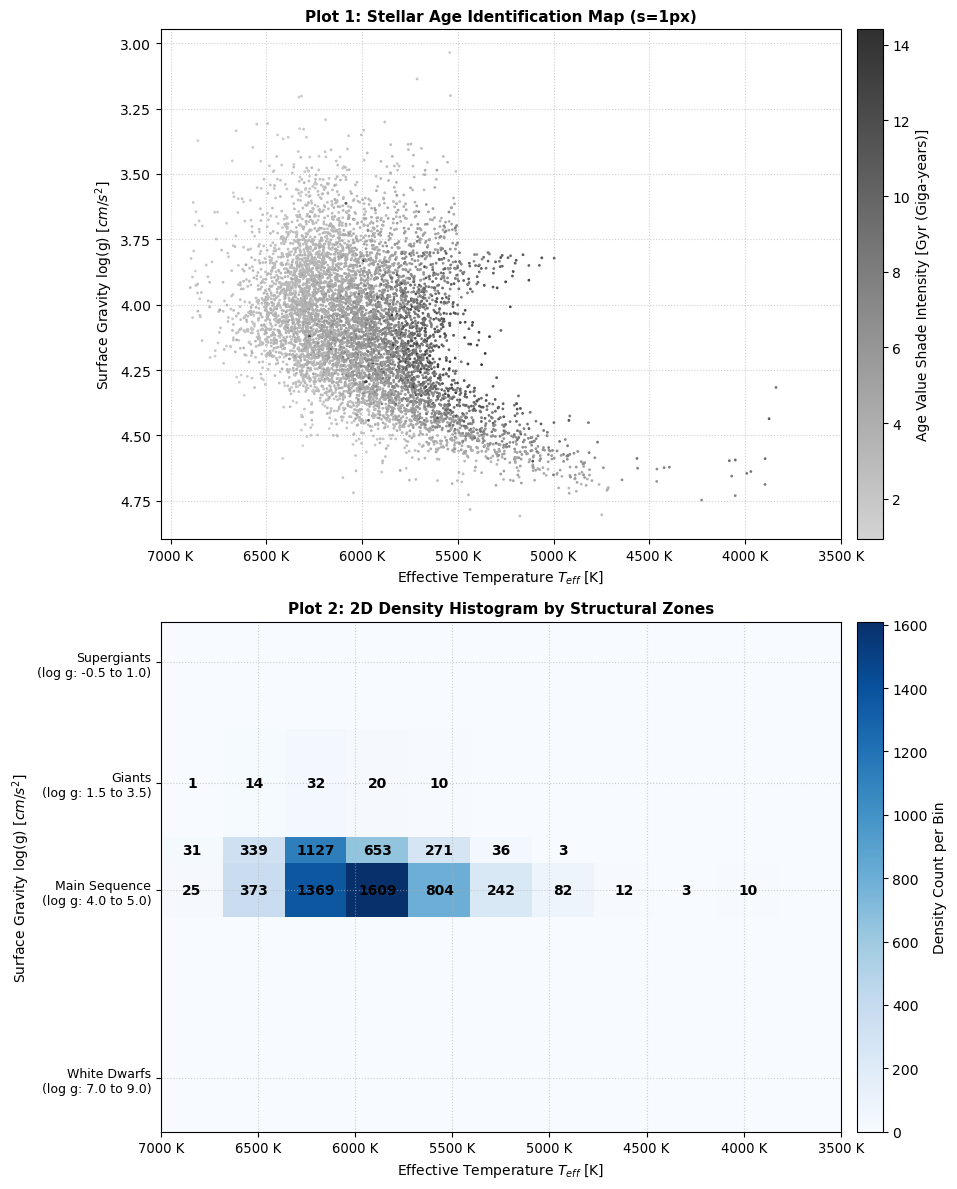

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 1. test data arrays
#logg = np.array([3.0356, 3.98712, 3.72595, 4.33929, 3.88533, 3.89015, 4.13021, 4.8082])
#teff = np.array([3838.1255, 6011.5874, 6339.5376, 5633.4771, 5996.9521, 6238.2358, 6161.7891, 6896.9507])
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])

# 2. Sort from highest to lowest Teff and rearrange logg and age correspondingly

# np.argsort(): Returns the indices that would sort an array in ascending order.
# [::-1]: Slices the index array in reverse to achieve a descending sort order (highest temperature first).
sort_indices = np.argsort(teff)[::-1]

# Array Slicing/Indexing: Reorders the data arrays based on the calculated sort_indices.
teff_sorted = teff[sort_indices]
logg_sorted = logg[sort_indices]
age_sorted = age[sort_indices]

# plt.subplots(): Creates a grid of subplots (2 rows, 1 column). 
# figsize sets width and height in inches. Returns a Figure object and an array of Axes objects (ax1, ax2).
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

# ----------------------------------------------------
# PLOT 1: Scatter plot tracking age values via color gradient
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR PLOT 1:
- X-Axis (Teff [K]): Represents the star's surface effective temperature. 
  It is inverted (hotter on the left, cooler on the right) matching standard Hertzsprung-Russell (H-R) diagram conventions, 
  because spectral classes move from hot (O, B) to cool (M).
- Y-Axis (log g [cm/s^2]): Represents the base-10 logarithm of surface gravity. 
  It is inverted (lower gravity at the top, higher gravity at the bottom). 
  Low surface gravity corresponds to physically bloated, expanded stellar atmospheres.
- Drawing Interpretation: This scatter plot maps discrete stars in an observational H-R diagram 
  (Kiel Diagram) configuration. The gray-scale intensity maps stellar age in Giga-years (Gyr). 
This allows astrophysicists to visualize how stars transition across evolutionary tracks over time. 
For example, older stars (darker shades) that have exhausted core hydrogen will actively diverge away from 
the unevolved main sequence toward lower log g zones.
"""

# mcolors.LinearSegmentedColormap.from_list(): Generates a custom colormap object 
# that smoothly interpolates linearly between the specified hex color values.
cmap1 = mcolors.LinearSegmentedColormap.from_list('custom_gray', ['#d3d3d3', '#303030'])

# ax.scatter(): Plots discrete points. 
# 'c' maps colors dynamically, 'cmap' applies the colormap, 's' sets point size (1 pixel), 
# and 'marker' defines the visual shape ('o' for circle).
sc1 = ax1.scatter(teff_sorted, logg_sorted, c=age_sorted, cmap=cmap1, s=1, marker='o')

# fig.colorbar(): Appends a scalar colorbar guide to the figure linked to the 'sc1' scatter plot data.
# 'ax' defines which subplot steals space for it, and 'pad' sets the fractional spacing between plot and colorbar.
cbar1 = fig.colorbar(sc1, ax=ax1, orientation='vertical', pad=0.02)

# cbar.set_label(): Applies a text label description to the colorbar scale.
cbar1.set_label('Age Value Shade Intensity [Gyr (Giga-years)]', fontsize=10)

# ax.set_title() / ax.set_ylabel(): Applies text labels to axes fields and plot frames.
ax1.set_title("Plot 1: Stellar Age Identification Map (s=1px)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Surface Gravity log(g) [$cm/s^2$]", fontsize=10)

# ax.invert_yaxis() / ax.invert_xaxis(): Reverses the direction of the numerical scales.
# Used here to conform to standard Hertzsprung-Russell (H-R) diagram conventions 
# (High temperature on the left, decreasing surface gravity toward the top).
ax1.invert_yaxis()
ax1.invert_xaxis()


# ----------------------------------------------------
# PLOT 2: 2D Density Histogram with Custom Subsets
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR PLOT 2:
- X-Axis (Teff [K]): Identical to Plot 1, tracking the hot-to-cold thermal profile of stellar atmospheres from left to right.
- Y-Axis (Stellar Structural Zones): Replaces raw numbers with explicit stellar luminosity class boundaries derived 
  from surface gravity (log g).
- Drawing Interpretation: This is a 2D density map binned into fundamental astrophysical structural zones. 
  The "Blues" color intensity and internal numbers reveal the density count (stellar population frequency) per bin. 
  * Supergiants (log g -0.5 to 1.0): Highly luminous, massive stars that have structurally ballooned outward, dropping surface gravity.
  * Giants (log g 1.5 to 3.5): Stars burning shell-hydrogen or core-helium that have evolved off the Main Sequence.
  * Main Sequence (log g 4.0 to 5.0): Stable, core-hydrogen-fusing dwarfs (like our Sun). This zone usually exhibits the highest density count due to the long lifespan of this phase.
  * White Dwarfs (log g 7.0 to 9.0): Ultra-dense, dead stellar remnants. They are extremely compact, yielding exceptionally high surface gravity.
"""

# Define specific y-bins for the custom stellar intervals requested
y_bins = [-0.5, 1.0, 1.5, 3.5, 4.0, 5.0, 7.0, 9.0]

# np.linspace(): Generates an array of 12 evenly-spaced numerical values across the range 3500 to 7000.
x_bins = np.linspace(3500, 7000, 12) 

# ax.hist2d(): Calculates and plots a 2D histogram. 
# Bins the coordinates into a grid defined by x_bins and y_bins, mapping bin population density to a color scale ('Blues').
# Returns a 2D array of counts, the calculated x/y edge arrays, and the QuadMesh image map object (im).
counts, xedges, yedges, im = ax2.hist2d(teff_sorted, logg_sorted, bins=[x_bins, y_bins], cmap='Blues')

# Print counts array as clear integer values to the console
# .astype(int): Casts numpy array elements from floats into integers.
#print("\n--- Plot 2 Bin Counts Array (Integers) ---")
#print(counts.astype(int))
#print("------------------------------------------\n")

# Annotate the integer count values inside each valid cell in Plot 2
# range() & len(): Iterates sequentially through index slots of the generated bin coordinate structures.
for i in range(len(x_bins)-1):
    for j in range(len(y_bins)-1):
        if counts[i, j] > 0:
            # Mathematical Midpoint Calculation: Finds the exact geometric spatial center of each cell.
            x_center = (x_bins[i] + x_bins[i+1]) / 2
            y_center = (y_bins[j] + y_bins[j+1]) / 2
            
            # ax.text(): Overlays structural text annotations directly onto the coordinate space.
            # 'ha' and 'va' manage horizontal and vertical alignment anchors respectively.
            ax2.text(x_center, y_center, str(int(counts[i, j])), 
                     color="black", ha="center", va="center", fontweight='bold', fontsize=10)

# fig.colorbar(): Creates the population density scale color indicator for the hist2d plot object (im).
cbar2 = fig.colorbar(im, ax=ax2, orientation='vertical', pad=0.02)
cbar2.set_label('Density Count per Bin', fontsize=10)

ax2.set_title("Plot 2: 2D Density Histogram by Structural Zones", fontsize=11, fontweight='bold')
ax2.set_ylabel("Surface Gravity log(g) [$cm/s^2$]", fontsize=10)

# Setup customized text labels mapping both classification name and range on the y-axis
label_positions = [0.25, 2.5, 4.5, 8.0]
label_texts = [
    "Supergiants\n(log g: -0.5 to 1.0)",
    "Giants\n(log g: 1.5 to 3.5)",
    "Main Sequence\n(log g: 4.0 to 5.0)",
    "White Dwarfs\n(log g: 7.0 to 9.0)"
]
# ax.set_yticks(): Explicitly dictates the precise numerical coordinate positions where ticks should sit.
ax2.set_yticks(label_positions)
# ax.set_yticklabels(): Substitutes numerical tick markings with readable text string elements.
ax2.set_yticklabels(label_texts, fontsize=9)

# Reverses axes orientations on the second canvas grid to match the standard stellar layout.
ax2.invert_yaxis()
ax2.invert_xaxis()


# ----------------------------------------------------
# Individual X-Axis Configuration & Formatting Labels
# ----------------------------------------------------
# np.arange(): Generates sequence of values starting at 3500 up to (but excluding) 7500, with increments of 500.
temperature_ticks = np.arange(3500, 7500, 500)

# List Comprehension: Loops over the array to build a string collection formatting numerical inputs with Kelvin units ("K").
temperature_labels = [f"{val} K" for val in temperature_ticks]

# Apply labels independently to both subplots so they appear on both x-axes
for ax in [ax1, ax2]:
    # ax.grid(): Enables coordinate grid meshes. 'linestyle' sets line dots and 'alpha' changes opacity.
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Customizes x-axis intervals using the generated arrays
    ax.set_xticks(temperature_ticks)
    ax.set_xticklabels(temperature_labels, fontsize=9.5)
    ax.set_xlabel("Effective Temperature $T_{eff}$ [K]", fontsize=10)
    
    # ax.tick_params(): Tweak design settings of ticks. labelbottom=True forces visibility even on stacked graphs.
    ax.tick_params(axis='x', labelbottom=True)

# plt.tight_layout(): Automatically recalculates subplots padding and positions 
# to keep text labels from overlapping adjacent graphics windows.
plt.tight_layout()

# plt.show(): Flushes background buffers, initializes the UI canvas engine window, and displays the final plot output.
plt.show()


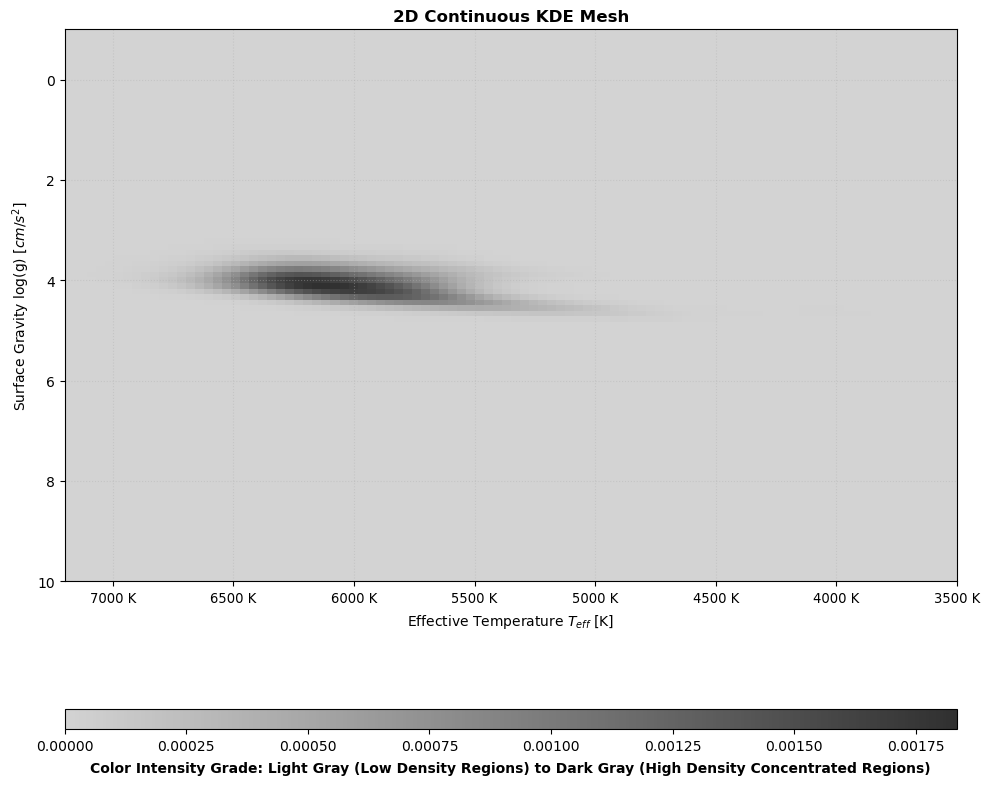

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import gaussian_kde

# 1. test data arrays
#logg = np.array([3.0356, 3.98712, 3.72595, 4.33929, 3.88533, 3.89015, 4.13021, 4.8082])
#teff = np.array([3838.1255, 6011.5874, 6339.5376, 5633.4771, 5996.9521, 6238.2358, 6161.7891, 6896.9507])
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])

# 2. Sort from highest to lowest Teff and rearrange logg and age correspondingly
# np.argsort(): Returns indices that sort an array in ascending order.
# [::-1]: Slices the array backward to make it descending (highest temperature first).
sort_indices = np.argsort(teff)[::-1]

# Array Slicing: Uses the sorted indices to realign all parallel physical vectors.
teff_sorted = teff[sort_indices]
logg_sorted = logg[sort_indices]
age_sorted = age[sort_indices]

# plt.subplots(): Initializes a new figure window framework. 
# Returns a Figure container object and an Axes coordinates plotting instance (ax1).
fig, ax1 = plt.subplots(figsize=(10, 8.5))

# ----------------------------------------------------
# 2D KDE Density Estimation (via pcolormesh)
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION & COORDINATE FRAMEWORK:
- X-Axis (Teff [K]): Represents the stellar surface effective temperature. By astronomical convention, the axis is inverted 
  so that hot stars (e.g., O, B spectral types) reside on the left, while cool stars (M dwarfs/giants) lie on the right. 
  This mirrors the historical layout of the Hertzsprung-Russell (H-R) diagram.
- Y-Axis (log g [cm/s^2]): The base-10 logarithm of surface gravity. It is inverted so that low gravity values sit at the top 
  and high gravity values sit at the bottom. Low surface gravity indicates large, physically bloated atmospheres 
  (Supergiants/Giants), whereas high surface gravity points to highly compact stars 
  (Main Sequence dwarfs and dense stellar remnants like White Dwarfs).
"""

# mcolors.LinearSegmentedColormap.from_list(): Synthesizes a new custom linear 
# colormap interpolating between the provided hexadecimal shade boundaries.
cmap1 = mcolors.LinearSegmentedColormap.from_list('custom_gray', ['#d3d3d3', '#303030'])

# np.linspace(): Generates 100 uniformly spaced steps across specified scientific limits.
x_grid = np.linspace(3500, 7200, 100)
y_grid = np.linspace(-1.0, 10.0, 100)

# np.meshgrid(): Takes 1D coordinate vectors and cross-multiplies them into a 
# 2D coordinate grid matrix system (X, Y) mapping the full field area.
X, Y = np.meshgrid(x_grid, y_grid)

# np.vstack(): Stacks individual arrays vertically into a unified 2-row multi-dimensional array matrix.
kde_input = np.vstack([teff_sorted, logg_sorted])

# gaussian_kde(): Initializes a non-parametric Kernel Density Estimator from SciPy.
# It acts as a statistical smoothing filter that reveals cluster concentrations without binning artifacts.
kde_engine = gaussian_kde(kde_input)

# Custom Bandwidth Modification: Lambda function overrides the default statistical scaling 
# factor (covariance multiplier) to cleanly smooth out sparse observational data inputs (8 points).
kde_engine.covariance_factor = lambda: 0.4  
kde_engine._compute_covariance() # Recalculates internal matrix parameters with the updated bandwidth rule.

# X.ravel(): Flattens the 2D grid matrix into a single continuous 1D row vector of points.
# The resulting 2-row matrix contains every coordinate permutation matching the evaluation mesh space.
grid_positions = np.vstack([X.ravel(), Y.ravel()])

# np.reshape(): Re-maps the evaluated 1D probability array back into the 2D shape of matrix X.
Z = np.reshape(kde_engine(grid_positions), X.shape)

# ax.pcolormesh(): Renders a pseudo-color mesh plot using irregular quadrilaterals.
# It uses the calculated relative probability values (Z) to map pixel color grades over the coordinate field.
mesh1 = ax1.pcolormesh(X, Y, Z, cmap=cmap1, shading='auto')


# ----------------------------------------------------
# Horizontal Colorbar Positioned BELOW the X-Axis
# ----------------------------------------------------
"""
ASTROPHYSICAL INTERPRETATION OF THE DRAWING:
- Unlike a classical H-R diagram displaying single points, this visualization displays a continuous 
  probability density map (Kiel Diagram structure) using a Gaussian smoothing kernel.
- The gray intensity gradient does NOT indicate stellar age. Instead, it measures the probability density functions 
  (the likelihood of finding a star inside those parameter spaces within your sample catalog).
  * High-Density Regions (Dark Gray Concentrated Hubs): Indicate highly populated steady-state evolutionary phases, 
    such as stable main sequence hydrogen burners, where stars spend the vast majority of their lifetimes.
  * Low-Density Regions (Light Gray Fading Into Background): Represent transient, rapid evolutionary phases 
    (e.g., giant branch crossings) or boundaries where few observed stars structurally exist.
"""

# fig.colorbar(): Creates a color key map object linked to the continuous scalar values of mesh1.
# 'pad' adjusts vertical offset separation, and 'aspect' manages the length-to-width ratio of the colorbar rectangle.
cbar1 = fig.colorbar(mesh1, ax=ax1, orientation='horizontal', pad=0.16, aspect=45)
cbar1.set_label('Color Intensity Grade: Light Gray (Low Density Regions) to Dark Gray (High Density Concentrated Regions)', 
                fontsize=10, fontweight='bold', labelpad=6)

# ax.set_title() / ax.set_ylabel() / ax.set_xlabel(): Assigns structural annotation texts to the coordinate canvas boundaries.
ax1.set_title("2D Continuous KDE Mesh", fontsize=12, fontweight='bold')
ax1.set_ylabel("Surface Gravity log(g) [$cm/s^2$]", fontsize=10)
ax1.set_xlabel("Effective Temperature $T_{eff}$ [K]", fontsize=10, labelpad=5)

# ax.invert_yaxis() / ax.invert_xaxis(): Reverses the default numeric index growth direction.
# This forces hot temperatures to run leftward and decreasing gravity to run upward, matching physical stellar catalogs.
ax1.invert_yaxis()
ax1.invert_xaxis()


# ----------------------------------------------------
# Axis Configuration & Formatting Labels
# ----------------------------------------------------
# np.arange(): Generates an integer range array from 3500 up to (but not including) 7500 in steps of 500.
temperature_ticks = np.arange(3500, 7500, 500)

# List Comprehension: Loops over the values to generate strings appended with Kelvin units ("K").
temperature_labels = [f"{val} K" for val in temperature_ticks]

# ax.grid(): Superimposes a background grid mesh over the canvas. 
# 'linestyle' selects a dotted format, 'alpha' defines transparency, and 'zorder' places it behind data marks.
ax1.grid(True, linestyle=':', alpha=0.4, zorder=1)

# Customizes the locations and text strings for the x-axis tick lines.
ax1.set_xticks(temperature_ticks)
ax1.set_xticklabels(temperature_labels, fontsize=9.5)

# ax.tick_params(): Modifies appearance parameters of ticks. labelbottom=True ensures visibility on the active axis frame.
ax1.tick_params(axis='x', labelbottom=True)
    
# ax.set_xlim() / ax.set_ylim(): Forces strict spatial boundaries on the displayed field window framework.
ax1.set_xlim(7200, 3500)
ax1.set_ylim(10.0, -1.0)

# plt.tight_layout(): Recalculates canvas layout geometry to prevent title or axis labels from overlapping.
plt.tight_layout()

# plt.show(): Flushes background image buffers and displays the final graphical user interface canvas.
plt.show()


### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

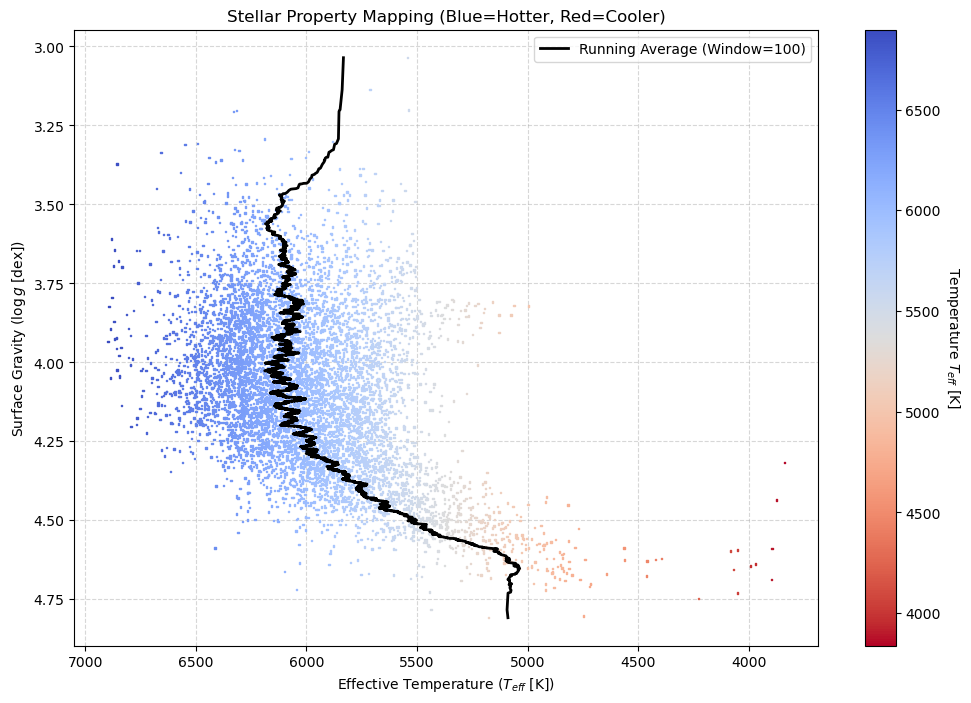

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

# 1. Define test data arrays
#logg = np.array([3.0356, 3.98712, 3.72595, 4.33929, 3.88533, 3.89015, 4.13021, 4.8082])
#teff = np.array([3838.1255, 6011.5874, 6339.5376, 5633.4771, 5996.9521, 6238.2358, 6161.7891, 6896.9507])
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])

# 2. Sort by logg to calculate a proper running average as a function of logg
# np.argsort(): Computes the index array that would sort 'logg' in ascending order.
# This sequence ensures the running filter tracks monotonic structural changes in gravity.
sort_idx = np.argsort(logg)

# Array Slicing/Indexing: Realigns both arrays using the calculated sorting permutation.
logg_sorted = logg[sort_idx]
teff_sorted_by_logg = teff[sort_idx]

# 3. Compute running average with Window Size = 100
window_size = 100

# uniform_filter1d(): Executes a fast 1D uniform boxcar filter along a sequence from SciPy.
# It computes a rolling arithmetic mean over a specified pixel 'size'. 
# 'mode=nearest' handles boundaries by duplicating edge pixels, avoiding mathematical truncation artifacts.
teff_running_avg = uniform_filter1d(teff_sorted_by_logg, size=window_size, mode='nearest')
logg_running_avg = logg_sorted

# 4. Plotting Setup
# plt.figure(): Allocates a blank figure container window canvas with specified dimensions (width, height) in inches.
plt.figure(figsize=(12,8))

# ----------------------------------------------------
# LAYER 1: Background Scatter Plot (Individual Stellar Points)
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 1 (SCATTER):
- X-Axis (Teff [K]): Maps the effective blackbody surface temperature of the stellar atmosphere. The scale is 
  inverted (hotter stars on the left, cooler stars on the right) to track standard spectral types (O, B, A, F, G, K, M).
- Y-Axis (log g [dex]): Measures the base-10 logarithm of surface gravity in cgs units. It is inverted 
  (low gravity at the top, high gravity at the bottom). Physically, stars with low log g are massive, expanded, 
  highly luminous Giants and Supergiants, while high log g stars are compact dwarfs.
- Interpretation: This creates a Kiel Diagram (an observational variant of the Hertzsprung-Russell Diagram). The individual 
  1-pixel marks represent discrete stars. The 'coolwarm_r' color map dynamically mirrors local physical reality: 
  highly energetic, hot blue stars cluster in the hot domain, blending down to cooler, lower-mass red stars.
"""
# plt.scatter(): Projects coordinate pairs onto the chart window. 
# 'c' links point colors to the values of teff; 'marker=","' forces 1-pixel square nodes;
# 's=1' minimizes marker surface overlap, and 'zorder=2' pins it below the trend line.
scatter = plt.scatter(teff, logg, c=teff, marker=',', s=1, cmap='coolwarm_r', zorder=2)


# ----------------------------------------------------
# LAYER 2: Foreground Vector Line (The Running Average)
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 2 (RUNNING AVERAGE):
- Axes Behavior: Evaluates effective temperature behavior as a direct function of decreasing structural surface gravity.
- Interpretation: The continuous black trend line represents a rolling empirical mean across the stellar distribution. 
  By tracking temperature variations against log g, this line acts as an observational proxy for a stellar evolutionary path. 
  It illustrates the main structural sequences of a population—such as tracing out the high-density Main Sequence spine, 
  and visualizing the temperature turn-off points where aging stars exhaust core hydrogen and tilt toward the Giant branches.
"""
# plt.plot(): Renders connected linear vector line paths between adjacent matrix coordinates.
# 'linewidth=2' enhances visual contrast on top of background density dots, and 'zorder=3' pushes it to the foreground.
plt.plot(teff_running_avg, logg_running_avg, color='black', linestyle='-', linewidth=2, 
         label=f'Running Average (Window={window_size})', zorder=3)


# Axis Labels & Custom Ticks 
# plt.xlabel() / plt.ylabel() / plt.title(): Inject text labels into the chart framework, 
# utilizing raw string styling blocks (r'...') to compile complex LaTeX math symbols.
plt.xlabel(r'Effective Temperature ($T_{eff}$ [K])')
plt.ylabel(r'Surface Gravity ($\log g$ [dex])')
plt.title(r'Stellar Property Mapping (Blue=Hotter, Red=Cooler)')

# plt.legend(): Superimposes a text label key frame box. 'loc' anchors its physical window quadrant.
plt.legend(loc='upper right')

# Standard H-R Diagram Axis Inversions
# plt.gca(): "Get Current Axes" pulls the underlying axis handle object. 
# invert_xaxis() / invert_yaxis() flip coordinates to conform to standard astronomical data layouts.
plt.gca().invert_xaxis()  
plt.gca().invert_yaxis()  

# Colorbar mapping the values to the reversed temperature gradient
# plt.colorbar(): Spawns a dedicated scalar color scale legend column referencing the scatter object's data range.
cbar = plt.colorbar(scatter)
# cbar.set_label(): Inscribes a tracking unit label to the color scale, rotated 270 degrees for vertical orientation.
cbar.set_label(r'Temperature $T_{eff}$ [K]', rotation=270, labelpad=15)

# plt.grid(): Projects an alignment coordinate mesh. 'linestyle' creates dashed tracks and 'alpha' softens its visibility.
plt.grid(True, linestyle='--', alpha=0.5)

# plt.show(): Flushes active display buffers, instantiates the local UI graphic loop, and outputs the finished plot frame.
plt.show()


### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

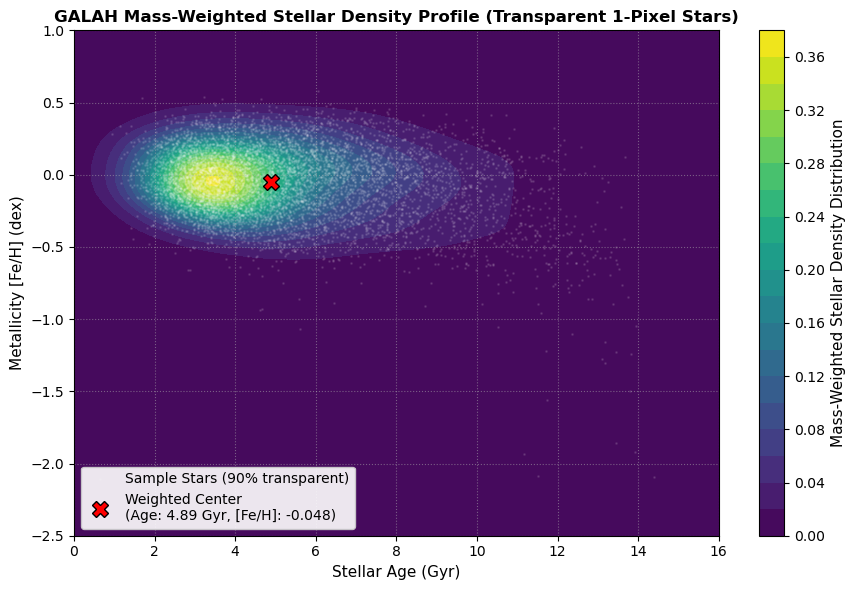

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# 1. Load test data arrays
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])
#feh = np.array([-2.094115, -0.070341, 0.104262, 0.240458, 0.254664, -0.045116, -0.291496, 0.577571])
#mass = np.array([0.493504, 1.141413, 1.540059, 0.997724, 1.389954, 1.331873, 1.06369, 2.083019])

# 2. Compute the exact mass-weighted metrics
# np.average(): Computes the weighted arithmetic mean of an array. 
# By supplying the 'mass' vector to the 'weights' parameter, the resulting scalar accounts for 
# the mass distribution of the stars rather than treating every sample item equally.
w_avg_age = np.average(age, weights=mass)
w_avg_feh = np.average(feh, weights=mass)

# 3. Establish continuous evaluation grid for 2D Density Evaluation
# np.mgrid: Synthesizes multi-dimensional coordinate mesh grids using slice notation.
# The '100j' suffix specifies generating exactly 100 complex-step, evenly-spaced indices 
# between the start and stop boundaries, forming a 100x100 matrix grid framework.
grid_age, grid_feh = np.mgrid[0:16:100j, -2.5:1.0:100j]

# np.vstack(): Stacks single-dimensional input arrays vertically to construct a unified 2D matrix.
# .ravel(): Flattens the 100x100 meshgrid matrices into 1D row sequences of 10,000 continuous pixels.
positions = np.vstack([grid_age.ravel(), grid_feh.ravel()])
data_points = np.vstack([age, feh])

# 4. Perform Mass-Weighted Gaussian Kernel Density Estimation (KDE)
# gaussian_kde(): Initializes a non-parametric Kernel Density Estimator from SciPy.
# The 'weights' parameter scales each star's statistical footprint relative to its physical mass.
# 'bw_method=0.4' manually anchors the smoothing bandwidth parameter to prevent overfitting small datasets.
kde = gaussian_kde(data_points, weights=mass, bw_method=0.4)

# kde(positions): Evaluates the computed kernel probability densities across all 10,000 grid nodes.
# .T: Transposes the matrix dimensions.
# np.reshape(): Re-maps the flat 1D evaluation sequence back into a structured 100x100 matrix mapping the grid shape.
density = np.reshape(kde(positions).T, grid_age.shape)

# 5. Generate Layout Map
# plt.figure(): Allocates a graphic display window canvas. 'dpi' (Dots Per Inch) sets resolution sharpness.
plt.figure(figsize=(9, 6), dpi=100)

# ----------------------------------------------------
# VISUAL LAYER 1: Continuous Contour Density Background
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 1 (CONTOUR MESH):
- X-Axis (Stellar Age [Gyr]): Displays time in Giga-years elapsed since the formation of the star. It maps the 
  chronological timeline of structural stellar birth across Galactic history up to 16 billion years ago.
- Y-Axis (Metallicity [Fe/H] [dex]): The logarithmic abundance ratio of Iron to Hydrogen relative to our Sun. 
  An [Fe/H] value of 0.0 is solar metallicity; negative values (e.g., -2.0) are highly metal-poor ancient stars, 
  and positive values mean metal-rich populations.
- Interpretation: The underlying filled color contour map displays the mass-weighted density field of a stellar survey 
  (like GALAH). It visualizes the "Age-Metallicity Relation" (AMR) of the Milky Way. The 'viridis' color spectrum maps 
  where the bulk of the galaxy's baryonic mass is locked up. It highlights standard chemical enrichment trends over time, 
  showing how younger populations generally concentrate around higher metal bands because interstellar gas becomes 
  increasingly enriched by supernova events over successive stellar generations.
"""
# plt.contourf(): Generates a filled 2D contour map over a coordinate grid.
# 'levels=20' partitions the density fields smoothly into 20 individual gradient contour step intervals.
contour = plt.contourf(grid_age, grid_feh, density, levels=20, cmap="viridis")

# plt.colorbar(): Draws a dedicated vertical scale column referencing the active scalar values of the contour layout.
cbar = plt.colorbar(contour)
# cbar.set_label(): Assigns a descriptive label string running alongside the colorbar frame.
cbar.set_label("Mass-Weighted Stellar Density Distribution", fontsize=11)


# ----------------------------------------------------
# VISUAL LAYER 2: Overlay Scatter Points & Barycentric Trend Marker
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 2 (DISCRETE OBJECTS & CENTER OF MASS):
- Coordinates Behavior: Tracks real catalog stars over the Age-[Fe/H] chemical distribution space.
- Interpretation: The tiny white scatter dots map individual observed stellar engines within the local sample. 
  The prominent red 'X' marker defines the calculated mass-weighted barycenter (center of mass) of this stellar population. 
  By weighting by mass instead of simple numbers, this marker tells astrophysicists where the center of mass of star 
  formation sits within this parameter window. This provides valuable insights for galactic chemical evolution models 
  tracing the history of star formation intensity across different Galactic sub-components (like the thin vs. thick disk).
"""
# plt.scatter(): Projects coordinate pairs onto the chart window as discrete marks. 
# 's=1' minimizes marker surface overlap, and 'alpha=0.1' sets high transparency to reveal the background mesh.
plt.scatter(age, feh, s=1, c='white', alpha=0.1, label='Sample Stars (90% transparent)')

# plt.plot(): Spawns line vector coordinates. Setting 'linestyle=None' and providing a 'marker' turns off 
# connecting line vectors to isolate a standalone custom symbol. 'markeredgecolor' outlines the symbol boundary.
plt.plot(w_avg_age, w_avg_feh, marker='X', color='red', markersize=12, 
         linestyle='None', markeredgecolor='black', label=f'Weighted Center\n(Age: {w_avg_age:.2f} Gyr, [Fe/H]: {w_avg_feh:.3f})')


# Aesthetics and Labels
# plt.title() / plt.xlabel() / plt.ylabel(): Apply text labels to their respective layout boundaries.
plt.title("GALAH Mass-Weighted Stellar Density Profile (Transparent 1-Pixel Stars)", fontsize=12, fontweight='bold')
plt.xlabel("Stellar Age (Gyr)", fontsize=11)
plt.ylabel("Metallicity [Fe/H] (dex)", fontsize=11)

# plt.xlim() / plt.ylim(): Mandate fixed boundary window limits on the coordinate axes.
plt.xlim(0, 16)
plt.ylim(-2.5, 1.0)

# plt.grid(): Projects an alignment coordinate mesh. 'linestyle' creates dotted lines and 'alpha' softens visibility.
plt.grid(True, linestyle=":", alpha=0.5)

# plt.legend(): Superimposes a text label key frame box. 'framealpha' adjusts the opacity of the background box container.
plt.legend(loc="lower left", framealpha=0.9)

# plt.tight_layout(): Recalculates canvas layout geometry to prevent title or axis labels from overlapping adjacent elements.
plt.tight_layout()

# plt.show(): Flushes active display buffers and outputs the finished plot frame to the user interface window loop.
plt.show()



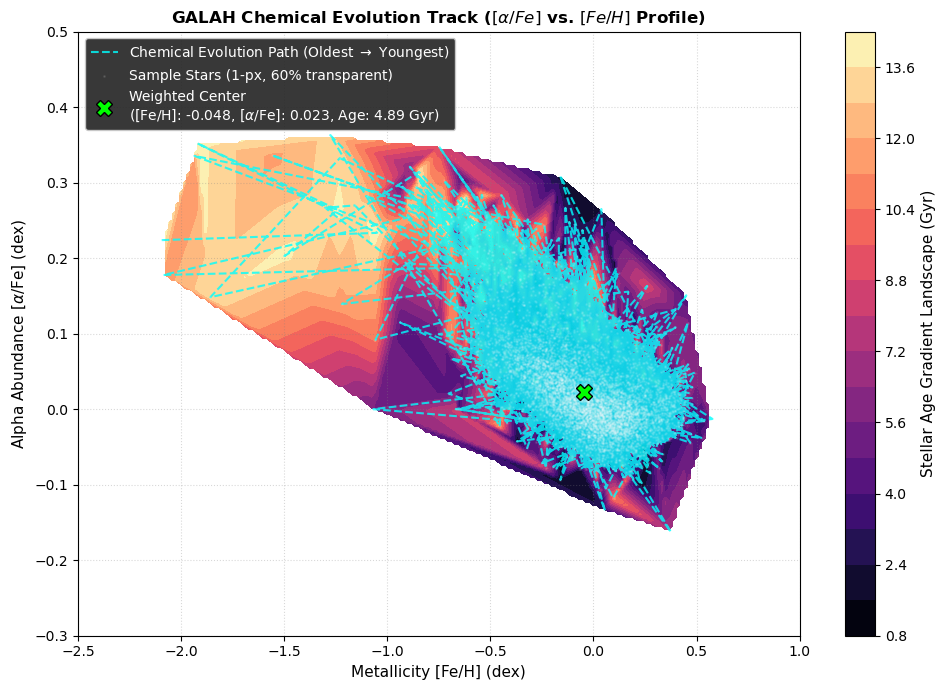

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# 1. Load data arrays
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])
#feh = np.array([-2.094115, -0.070341, 0.104262, 0.240458, 0.254664, -0.045116, -0.291496, 0.577571])
#mass = np.array([0.493504, 1.141413, 1.540059, 0.997724, 1.389954, 1.331873, 1.06369, 2.083019])
#afe = np.array([-0.16278, 0.002338, 0.029315, 0.039954, 0.000754, -0.025195, 0.038777, 0.362819])

# 2. Compute the exact mass-weighted metrics across all dimensions
# np.average(): Computes the weighted arithmetic mean of an array. 
# Using 'mass' as the weight factor ensures that these parameters represent the true distribution 
# of stellar mass across the sample, rather than treating low-mass and massive stars identically.
w_avg_feh = np.average(feh, weights=mass)
w_avg_afe = np.average(afe, weights=mass)
w_avg_age = np.average(age, weights=mass)

# 3. Create a sorted chronological sequence (Oldest -> Youngest) for the chemical track
# np.argsort(): Computes an index array that would sort 'age' in ascending order.
# [::-1]: Reverses that index sequence to achieve a descending sort (oldest stars first).
sort_idx = np.argsort(age)[::-1]

# Array Slicing/Indexing: Reorders the vectors into a chronological timeline using the sorted indices.
age_sorted = age[sort_idx]
feh_sorted = feh[sort_idx]
afe_sorted = afe[sort_idx]

# 4. Generate continuous coordinate space for background Age landscape mapping
# np.mgrid: Generates multi-dimensional coordinate mesh grids using slice notation.
# The '200j' suffix creates 200 complex-step, evenly-spaced index numbers from the specified start 
# to end points, producing a high-resolution 200x200 grid matrix system.
grid_feh, grid_afe = np.mgrid[-2.5:1.0:200j, -0.3:0.5:200j]

# griddata(): Performs multi-dimensional unstructured data interpolation from SciPy.
# Fits a continuous surface over irregular data coordinates ((feh, afe) -> age) and projects it 
# onto the structured grid arrays. 'method="linear"' uses Delaunay triangulation to linearly interpolate values.
grid_age = griddata((feh, afe), age, (grid_feh, grid_afe), method='linear')

# 5. Generate Layout Map
# plt.figure(): Allocates a graphic display window canvas frame. 'dpi' manages resolution sharpness.
plt.figure(figsize=(10, 7), dpi=100)

# ----------------------------------------------------
# VISUAL LAYER 1: Continuous Interpolated Age Contour Landscape
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 1 (CONTOUR BACKGROUND):
- X-Axis (Metallicity [Fe/H] [dex]): The base-10 logarithm of the iron-to-hydrogen ratio compared to the Sun. 
  It represents a galaxy's overall chemical maturity. Values around 0.0 are solar-like, while negative values 
  indicate pristine gas left behind by primitive gas clouds.
- Y-Axis (Alpha Abundance [\alpha/Fe] [dex]): Measures the ratio of alpha-process elements (e.g., O, Mg, Si, Ca, Ti) 
  relative to iron. This acts as a cosmic stopwatch: high [\alpha/Fe] implies rapid star formation dominated by short-lived 
  Type II Supernovae, while low [\alpha/Fe] reveals long-term enrichment from delayed Type Ia Supernovae.
- Interpretation: The underlying colored 'magma' contour map visualizes the age topology across this chemical plane. 
  It maps out the distinct chemical sub-structures of our Milky Way Galaxy. It illustrates how the oldest stellar systems 
  are structurally segregated into a high-alpha, low-metallicity pocket (the Galactic Thick Disk), transitioning into a 
  younger, lower-alpha sequence (the Galactic Thin Disk).
"""
# plt.contourf(): Generates a filled 2D contour map over a structured coordinate system.
# 'levels=15' divides the continuous grid values into 15 discrete, step-wise filled color zones.
contour = plt.contourf(grid_feh, grid_afe, grid_age, levels=15, cmap="magma")

# plt.colorbar(): Spawns a dedicated scalar color scale legend bar on the margin linked to the contour intensities.
cbar = plt.colorbar(contour)
# cbar.set_label(): Assigns a descriptive string label running vertically alongside the colorbar framework.
cbar.set_label("Stellar Age Gradient Landscape (Gyr)", fontsize=11)


# ----------------------------------------------------
# VISUAL LAYER 2: Evolutionary Track & Integrated Mass Barycenter
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 2 (CHRONOLOGICAL TRACK & MARKERS):
- Coordinates Behavior: Traces pathways and specific focal points directly inside the [\alpha/Fe] vs. [Fe/H] space.
- Interpretation: The cyan dashed line maps out the explicit, chronological chemical trajectory of star-forming gas 
  over time (from oldest to youngest). This line tracks the "chemical enrichment history" of the galaxy. It shows how the 
  early interstellar medium was rapidly infused with alpha elements before fading downwards as iron-producing Type Ia 
  supernovae took over. The discrete 1-pixel white dots represent observed individual target stars, while the bold lime green 
  'X' marker marks the integrated mass-weighted chemical barycenter, identifying the geometric center of mass of the stellar population.
"""
# plt.plot(): Connects ordered coordinate arrays via linear vector line elements.
# 'alpha=0.8' gives 80% opacity, allowing the underlying background contour structure to show through.
plt.plot(feh_sorted, afe_sorted, color='cyan', linestyle='--', linewidth=1.5, 
         alpha=0.8, label='Chemical Evolution Path (Oldest $\\rightarrow$ Youngest)')

# plt.scatter(): Projects coordinate pairs onto the chart window as discrete marks. 
# 's=1' minimizes marker size, and 'alpha=0.1' sets high transparency to keep from blocking the background mesh.
plt.scatter(feh, afe, s=1, c='white', alpha=0.1, zorder=5, label='Sample Stars (1-px, 60% transparent)')

# plt.plot(): Spawns line vector coordinates. Setting 'linestyle="None"' isolates a standalone marker symbol.
# 'zorder=6' places this object on the highest visual layer, preventing background elements from clipping it.
plt.plot(w_avg_feh, w_avg_afe, marker='X', color='lime', markersize=12, 
         linestyle='None', markeredgecolor='black', zorder=6,
         label=f'Weighted Center\n([Fe/H]: {w_avg_feh:.3f}, [$\\alpha$/Fe]: {w_avg_afe:.3f}, Age: {w_avg_age:.2f} Gyr)')


# Aesthetics and Labels
# plt.title() / plt.xlabel() / plt.ylabel(): Apply text labels to their respective layout frames.
# Raw string block format (r'...') parses complex LaTeX mathematical strings and Greek characters.
plt.title("GALAH Chemical Evolution Track ($[\\alpha/Fe]$ vs. $[Fe/H]$ Profile)", fontsize=12, fontweight='bold')
plt.xlabel("Metallicity [Fe/H] (dex)", fontsize=11)
plt.ylabel("Alpha Abundance [$\\alpha$/Fe] (dex)", fontsize=11)

# plt.xlim() / plt.ylim(): Mandate fixed boundary window limits on the coordinate axes.
plt.xlim(-2.5, 1.0)
plt.ylim(-0.3, 0.5)

# plt.grid(): Projects an alignment coordinate mesh. 'linestyle' sets a dotted format, and alpha softens its visibility.
plt.grid(True, linestyle=":", alpha=0.3, color='gray')

# plt.legend(): Superimposes a text label key frame box. 'facecolor' colors the box fill, and 'labelcolor' styles the text.
plt.legend(loc="upper left", framealpha=0.9, facecolor='#222222', labelcolor='white')

# plt.tight_layout(): Recalculates canvas layout geometry to prevent text labels from overlapping adjacent elements.
plt.tight_layout()

# plt.show(): Flushes active display buffers and outputs the finished plot frame to the user interface window loop.
plt.show()


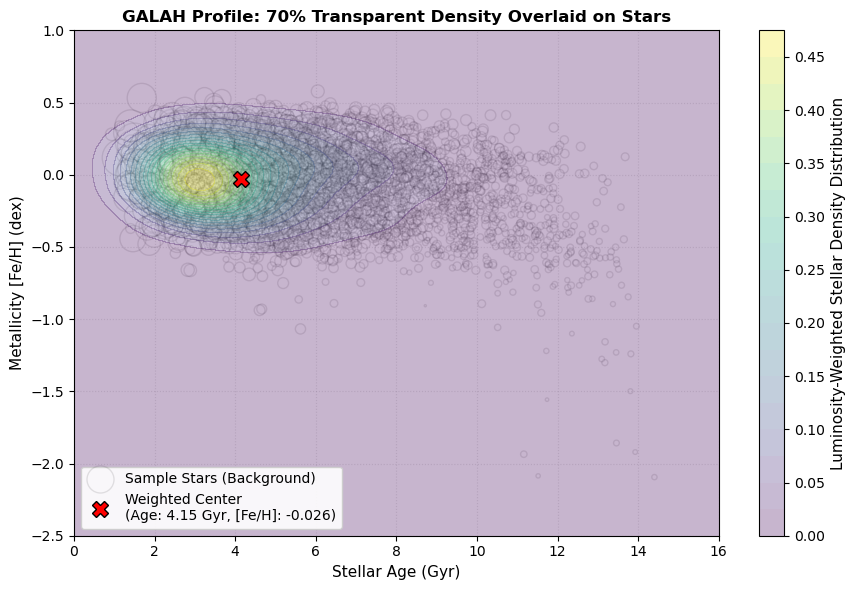

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# 1. Load data arrays
#age = np.array([0.93525, 5.50895, 2.3795, 6.99734, 3.67235, 3.48878, 5.1663, 14.40223])
#feh = np.array([-2.094115, -0.070341, 0.104262, 0.240458, 0.254664, -0.045116, -0.291496, 0.577571])
#lum = np.array([0.05931475056804868, 1.69734943, 5.62534854, 0.99092703, 3.73251628, 3.14667043, 1.28014836, 18.826644644558908])

# 2. Compute the exact luminosity-weighted metrics
# np.average(): Calculates the weighted arithmetic mean of an array. 
# Supplying the 'lum' vector to the 'weights' parameter ensures that the resulting averages 
# reflect the integrated light contribution of the stars rather than treating all sample items equally.
w_avg_age = np.average(age, weights=lum)
w_avg_feh = np.average(feh, weights=lum)

# 3. Establish continuous evaluation grid for 2D Density Evaluation
# np.mgrid: Synthesizes multi-dimensional coordinate mesh grids using slice notation.
# The '100j' suffix generates exactly 100 complex-step, evenly spaced indices between 
# the specified boundaries, building a high-resolution 100x100 matrix coordinate grid.
grid_age, grid_feh = np.mgrid[0:16:100j, -2.5:1.0:100j]

# np.vstack(): Stacks single-dimensional input arrays vertically to construct a unified 2D matrix.
# .ravel(): Flattens the 100x100 meshgrid matrices into 1D row vectors of 10,000 continuous pixels.
positions = np.vstack([grid_age.ravel(), grid_feh.ravel()])
data_points = np.vstack([age, feh])

# 4. Perform Luminosity-Weighted Gaussian Kernel Density Estimation (KDE)
# gaussian_kde(): Initializes a non-parametric Kernel Density Estimator from SciPy.
# The 'weights' parameter biases each star's statistical footprint relative to its absolute luminosity.
# 'bw_method=0.4' fixes the smoothing bandwidth scale factor to prevent overfitting sparse datasets.
kde = gaussian_kde(data_points, weights=lum, bw_method=0.4)

# kde(positions): Evaluates the computed kernel probability densities across all 10,000 grid nodes.
# .T: Transposes the matrix dimensions.
# np.reshape(): Re-maps the flat 1D evaluation sequence back into a structured 100x100 matrix matching the grid shape.
density = np.reshape(kde(positions).T, grid_age.shape)

# 5. Generate Layout Map
# plt.figure(): Allocates a graphic display window canvas frame. 'dpi' manages resolution sharpness.
plt.figure(figsize=(9, 6), dpi=100)

# ----------------------------------------------------
# VISUAL LAYER 1: Background Scatter Plot (Luminosity-Scaled Stars)
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 1 (BACKGROUND SCATTER):
- X-Axis (Stellar Age [Gyr]): Displays the absolute time elapsed since the star's birth, tracking stellar 
  chronology across Cosmic time up to 16 billion years ago.
- Y-Axis (Metallicity [Fe/H] [dex]): The base-10 logarithm of the Iron-to-Hydrogen ratio compared to the Sun. 
  Negative values indicate ancient metal-poor gas environments, while values near 0.0 or higher are solar/metal-rich.
- Interpretation: The individual white scatter circles represent discrete stars mapped in chemical evolution space. 
  Crucially, their visual sizing (s=lum*40) directly mirrors their physical luminosity. Highly evolved, energy-intensive 
  Giants or Supergiants appear as broad, large spheres, while unevolved, faint Main Sequence dwarfs appear as tiny specks. 
  This allows researchers to visually cross-reference individual evolutionary tracking states against their chronological ages.
"""
# plt.scatter(): Projects coordinate pairs onto the chart window as discrete marks. 
# 's=lum*40' dynamically scales the marker area by luminosity, 'edgecolor' outlines the bubbles, 
# 'alpha=0.1' applies 90% transparency, and 'zorder=1' places this base layer at the bottom.
plt.scatter(age, feh, s=lum*40, c='white', edgecolor='black', alpha=0.1, zorder=1, label='Sample Stars (Background)')


# ----------------------------------------------------
# VISUAL LAYER 2: Overlaid Continuous KDE Contours & Absolute Light Barycenter
# ----------------------------------------------------
"""
ASTROPHYSICAL DESCRIPTION FOR LAYER 2 (DENSITY CONTOURS & LIGHT BARYCENTER):
- Coordinates Behavior: Analyzes continuous probabilistic density profiles across the global Age-[Fe/H] field.
- Interpretation: The smooth 'viridis' contour grid overlaid on top represents a continuous probability field 
  weighted by stellar light profile contributions. Instead of counting raw numbers of stars, this layout tracks where 
  the dominant sources of stellar light emission originate. Highly luminous giant stars heavily influence the contour topology. 
  The bold red 'X' marker defines the absolute luminosity-weighted barycenter (center of light). Comparing this to a 
  mass-weighted center reveals vital details about a population's post-main-sequence evolution, showing how a few evolved 
  giant stars can dominate a stellar population's light output even if they don't contain most of its mass.
"""
# plt.contourf(): Generates a filled 2D contour map over a structured coordinate system.
# 'levels=20' partitions the continuous field into 20 step-wise color zones, and 'alpha=0.3' makes it 70% transparent.
contour = plt.contourf(grid_age, grid_feh, density, levels=20, cmap="viridis", alpha=0.3, zorder=2)

# plt.colorbar(): Spawns a dedicated scalar color scale legend column referencing the active contour data boundaries.
cbar = plt.colorbar(contour)
# cbar.set_label(): Assigns a descriptive string label running vertically alongside the colorbar framework.
cbar.set_label("Luminosity-Weighted Stellar Density Distribution", fontsize=11)

# plt.plot(): Spawns line vector coordinates. Setting 'linestyle="None"' isolates a standalone marker symbol.
# 'zorder=3' places this marker on the absolute top layer, preventing underlying transparency sheets from dulling its color.
plt.plot(w_avg_age, w_avg_feh, marker='X', color='red', markersize=12, 
         linestyle='None', markeredgecolor='black', zorder=3,
         label=f'Weighted Center\n(Age: {w_avg_age:.2f} Gyr, [Fe/H]: {w_avg_feh:.3f})')


# Aesthetics and Labels
# plt.title() / plt.xlabel() / plt.ylabel(): Apply text labels to their respective layout boundaries.
plt.title("GALAH Profile: 70% Transparent Density Overlaid on Stars", fontsize=12, fontweight='bold')
plt.xlabel("Stellar Age (Gyr)", fontsize=11)
plt.ylabel("Metallicity [Fe/H] (dex)", fontsize=11)

# plt.xlim() / plt.ylim(): Mandate fixed boundary window limits on the coordinate axes.
plt.xlim(0, 16)
plt.ylim(-2.5, 1.0)

# plt.grid(): Projects an alignment coordinate grid. 'zorder=0' ensures the grid mesh sits completely behind the data.
plt.grid(True, linestyle=":", alpha=0.3, zorder=0)

# plt.legend(): Superimposes a text label key frame box. 'framealpha' adjusts the opacity of the background box container.
plt.legend(loc="lower left", framealpha=0.9)

# plt.tight_layout(): Recalculates canvas layout geometry to prevent text labels from overlapping adjacent elements.
plt.tight_layout()

# plt.show(): Flushes active display buffers and outputs the finished plot frame to the user interface window loop.
plt.show()

